# AI-Powered Job Market Intelligence & Salary Prediction System
## Module 1 — Task 1: In-Depth Dataset Exploration & Quality Audit

**Target File:** `data/raw/india_job_market_messy_31150_records.csv`  
**Reference Docs:** `data/raw/DATASET_README_AND_TASKS.txt`, `AI_Job_Market_Intelligence_Project_Requirements.pdf`  

### Exploration Objectives:
1. Load and inspect the raw tech job postings dataset.
2. Audit schema, column data types, missingness, and duplicate listings.
3. Identify categorical anomalies, text casing discrepancies, and alias variations.
4. Validate numerical distributions and discover corrupted salary/experience records.
5. Extract and analyze frequently requested technical skills from unstructured fields.
6. Generate analytical visualizations to establish data quality baselines for downstream modeling.

> **Important Note:** This dataset is a synthetic research dataset simulating Indian tech hiring listings. It contains deliberately injected duplicates, corrupted salary entries, and noisy categories for realistic data science practice.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print('Libraries imported and visualization styling initialized.')

Libraries imported and visualization styling initialized.


### 1. Dataset Loading, Dimensions & Column Schema
We load the raw CSV file from `data/raw/` without altering or removing any records.

In [2]:
# Robust path resolution for running from project root or notebooks/ dir
candidate_paths = [
    os.path.join('..', 'data', 'raw', 'india_job_market_messy_31150_records.csv'),
    os.path.join('data', 'raw', 'india_job_market_messy_31150_records.csv')
]
DATA_PATH = next((p for p in candidate_paths if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError('Dataset file not found in candidate paths: ' + str(candidate_paths))

print(f'Loading dataset from: {DATA_PATH}')
df = pd.read_csv(DATA_PATH)
print(f'Dataset Dimensions: {df.shape[0]:,} Rows | {df.shape[1]} Columns')
print('\nColumn Listing:')
for idx, col in enumerate(df.columns, 1):
    print(f' {idx:02d}. {col}')


Loading dataset from: ..\data\raw\india_job_market_messy_31150_records.csv


Dataset Dimensions: 31,150 Rows | 20 Columns

Column Listing:
 01. job_id
 02. job_title
 03. company_name
 04. city
 05. state
 06. experience_level
 07. experience_years
 08. education
 09. employment_type
 10. work_mode
 11. salary_min_lpa
 12. salary_max_lpa
 13. salary_currency
 14. skills_required
 15. job_description
 16. company_size
 17. industry
 18. posted_date
 19. data_source
 20. job_url


### 2. Data Types and Schema Inspection
Let us inspect non-null counts, data types, and memory consumption.

In [3]:
# Concise info and schema table
schema_summary = pd.DataFrame({
    'Data Type': df.dtypes.astype(str),
    'Non-Null Count': df.notnull().sum(),
    'Null Count': df.isnull().sum(),
    'Null %': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique()
})
schema_summary

,Data Type,Non-Null Count,Null Count,Null %,Unique Values
job_id,object,31150,0,0.00,30250
job_title,object,31150,0,0.00,24
company_name,object,30444,706,2.27,15
city,object,30575,575,1.85,19
state,object,30582,568,1.82,12
experience_level,object,30808,342,1.10,8
experience_years,float64,30378,772,2.48,21
education,object,28875,2275,7.30,5
employment_type,object,31150,0,0.00,7
work_mode,object,30719,431,1.38,6


### 3. First 10 Records Inspection

In [4]:
df.head(10)

,job_id,job_title,company_name,city,state,experience_level,experience_years,education,employment_type,work_mode,salary_min_lpa,salary_max_lpa,salary_currency,skills_required,job_description,company_size,industry,posted_date,data_source,job_url
0,JOB000097,Software Engineer,PixelGrid,Hyderabad,Telangana,Junior,2.00,Any Degree,Full-time,Remote,8.01,11.25,INR,"dbt, Kubernetes, Git, FastAPI, NLP, Deep Lear...",Seeking a Software Engineer with experience in...,201-500,Telecom,2026-06-16,Job Portal B,https://example.test/jobs/000097
1,JOB019053,MLOps Engineer,NextGen Systems,Coimbatore,Tamil Nadu,Junior,2.00,Bachelor's,Internship,On-site,7.68,NaN,INR,"JavaScript, GCP, Spark, Python, Docker, Linux,...",Seeking a MLOps Engineer with experience in Ja...,NaN,Product,2026-03-19,Job Portal B,https://example.test/jobs/019053
2,JOB012931,AI Engineer,CloudAxis,Gurugram,Haryana,Junior,2.00,Master's,Full-time,On-site,11.40,13.92,INR,"Hadoop, Airflow, Azure, Python, Machine Learning",Seeking a AI Engineer with experience in Hadoo...,201-500,Telecom,2026-02-03,Job Portal B,https://example.test/jobs/012931
3,JOB009397,Data Engineer,Aster Digital,Kochi,Kerala,Junior,2.00,Any Degree,Full-time,Hybrid,NaN,9.04,INR,"AWS, Hadoop, Django, Machine Learning, Python,...",Seeking a Data Engineer with experience in AWS...,51-200,E-commerce,2026-06-01,Company Website,https://example.test/jobs/009397
4,JOB026452,Machine Learning Engineer,FinEdge,Gurugram,Haryana,Mid-level,5.00,Any Degree,Contract,Remote,NaN,19.88,INR,"GCP, Java, TensorFlow, JavaScript, Hadoop, Mac...",Seeking a Machine Learning Engineer with exper...,NaN,Product,2025-02-25,Recruiter,https://example.test/jobs/026452
5,JOB001913,Data Engineer,QuantLeaf,Jaipur,Rajasthan,junior,5.00,Master's,Full-time,On-site,8.34,11.64,INR,"Scikit-learn, PyTorch, Computer Vision, Airflow",Seeking a Data Engineer with experience in Sci...,201-500,Telecom,2024-04-21,Job Portal B,https://example.test/jobs/001913
6,JOB025784,Data Analyst,Vertex Labs,Mumbai,Maharashtra,Fresher,0.00,Master's,Internship,Remote,3.87,4.58,INR,"NLP, GCP, Pandas",NaN,501-1000,E-commerce,2025-10-05,Job Portal A,https://example.test/jobs/025784
7,JOB026954,Python Developer,TechNova,Chennai,Tamil Nadu,Lead,16.00,Any Degree,Full-time,On-site,10.92,15.15,INR,"Machine Learning, Deep Learning, Computer Visi...",Seeking a Python Developer with experience in ...,501-1000,IT Services,2025-05-09,Job Portal A,https://example.test/jobs/026954
8,JOB006355,Machine Learning Engineer,CodeCraft,Delhi NCR,Delhi,Senior,8.00,Master's,Full-time,On-site,28.82,NaN,INR,"Git, Power BI, FastAPI, SQL, Python, Machine L...",Seeking a Machine Learning Engineer with exper...,51-200,E-commerce,2026-04-22,Company Website,https://example.test/jobs/006355
9,JOB028967,Data Engineer,CodeCraft,Hyderabad,Telangana,Senior,8.00,PhD,Full-time,Hybrid,14.34,17.17,INR,"Python, NLP, Excel, Pandas, Hadoop, Deep Learning",Seeking a Data Engineer with experience in Pyt...,NaN,IT Services,2026-05-10,Company Website,https://example.test/jobs/028967


### 4. Last 10 Records Inspection

In [5]:
df.tail(10)

,job_id,job_title,company_name,city,state,experience_level,experience_years,education,employment_type,work_mode,salary_min_lpa,salary_max_lpa,salary_currency,skills_required,job_description,company_size,industry,posted_date,data_source,job_url
31140,JOB006266,AI Engineer,QuantLeaf,Kolkata,West Bengal,Mid-level,3.00,Any Degree,Full-time,On-site,14.42,19.89,INR,"Tableau, Flask, Deep Learning, Computer Vision...",Seeking a AI Engineer with experience in Table...,1000+,Healthcare Tech,2026-07-25,Job Portal B,https://example.test/jobs/006266
31141,JOB022119,Business Analyst,PixelGrid,Hyderabad,Telangana,Fresher,0.00,Diploma,Full-time,On-site,4.16,5.95,INR,"PyTorch, Deep Learning, Tableau, Azure, dbt",Seeking a Business Analyst with experience in ...,501-1000,FinTech,2024-05-31,Company Website,https://example.test/jobs/022119
31142,JOB011285,Business Analyst,InnoSoft,Ahmedabad,Gujarat,Senior,8.00,Diploma,Full-time,Hybrid,11.31,NaN,INR,"Kubernetes, TensorFlow, Power BI",Seeking a Business Analyst with experience in ...,201-500,Telecom,2026-05-04,Job Portal A,https://example.test/jobs/011285
31143,JOB011965,Business Analyst,Vertex Labs,Thiruvananthapuram,Kerala,Mid-level,3.00,Bachelor's,Full-time,On-site,5.82,NaN,INR,"GCP, Flask, Spark, Pandas, Python, FastAPI, Ta...",Seeking a Business Analyst with experience in ...,201-500,E-commerce,2025-11-20,Job Portal A,https://example.test/jobs/011965
31144,JOB021576,NLP Engineer,Vertex Labs,Mumbai,Maharashtra,Senior,6.00,Any Degree,Full-time,On-site,-1.74,29.56,INR,"Python, Pandas, Excel, PyTorch, Azure, Machine...",Seeking a NLP Engineer with experience in Pyth...,501-1000,IT Services,2025-04-25,Company Website,https://example.test/jobs/021576
31145,JOB029803,Business Analyst,Vertex Labs,Mumbai,Maharashtra,Mid-level,5.00,Diploma,Full-time,On-site,7.70,9.53,INR,"Machine Learning, Python, Computer Vision",Seeking a Business Analyst with experience in ...,501-1000,Consulting,2026-03-15,Recruiter,https://example.test/jobs/029803
31146,JOB005391,Software Engineer,NextGen Systems,Jaipur,Rajasthan,Mid-level,5.00,Diploma,Full-time,Hybrid,7.20,8.71,INR,"FastAPI, Computer Vision, Deep Learning, Panda...",Seeking a Software Engineer with experience in...,1-50,E-commerce,2024-07-23,Job Portal A,https://example.test/jobs/005391
31147,JOB000861,NLP Engineer,Orbit Technologies,Gurugram,Haryana,Mid-level,4.00,Diploma,Full-time,On-site,10.48,NaN,INR,"Machine Learning, SQL, Kubernetes, PyTorch, Co...",Seeking a NLP Engineer with experience in Mach...,1000+,Consulting,2026-06-24,Job Portal B,https://example.test/jobs/000861
31148,JOB015796,Software Engineer,Vertex Labs,Jaipur,Rajasthan,Fresher,0.00,Any Degree,Full-time,Hybrid,4.57,NaN,INR,"dbt, Computer Vision, GCP, NLP, Azure, Django...",Seeking a Software Engineer with experience in...,51-200,Consulting,2026-07-08,Job Portal A,https://example.test/jobs/015796
31149,JOB023655,Data Engineer,Vertex Labs,Gurugram,Haryana,Mid-level,5.00,PhD,Full-time,On-site,13.83,21.93,INR,"Kubernetes, NumPy, dbt, TensorFlow, FastAPI, ...",Seeking a Data Engineer with experience in Kub...,1000+,E-commerce,2024-09-03,Job Portal B,https://example.test/jobs/023655


### 5. Detailed Missing Values Analysis
Here we measure missingness across all features to isolate critical data gaps.

In [6]:
null_counts = df.isnull().sum()
missing_cols = null_counts[null_counts > 0].sort_values(ascending=False)

missing_df = pd.DataFrame({
    'Missing Count': missing_cols,
    'Missing Percentage (%)': (missing_cols / len(df) * 100).round(2)
})

print(f'Total Columns with Missing Values: {len(missing_df)} out of {df.shape[1]}')
missing_df

Total Columns with Missing Values: 14 out of 20


,Missing Count,Missing Percentage (%)
salary_max_lpa,7459,23.95
salary_min_lpa,7331,23.53
company_size,3067,9.85
education,2275,7.30
skills_required,1731,5.56
industry,1357,4.36
job_description,1176,3.78
experience_years,772,2.48
company_name,706,2.27
city,575,1.85


### 6. Duplicate Records Audit
We identify exact duplicates across all columns as well as near-duplicate job postings.

In [7]:
exact_dupes = df.duplicated().sum()
print(f'Exact Duplicate Rows: {exact_dupes:,} ({exact_dupes / len(df) * 100:.2f}% of total dataset)')

# Inspect sample exact duplicates
if exact_dupes > 0:
    duplicate_sample = df[df.duplicated(keep=False)].sort_values(by=['job_title', 'company_name']).head(6)
    print('\nSample exact duplicate pairs:')
    display(duplicate_sample[['job_id', 'job_title', 'company_name', 'city', 'salary_min_lpa', 'salary_max_lpa']])

# Near-duplicates check (ignoring synthetic job_id and job_url)
content_cols = [c for c in df.columns if c not in ['job_id', 'job_url']]
near_dupes = df.duplicated(subset=content_cols).sum()
print(f'\nPostings with identical content (excluding job_id & job_url): {near_dupes:,}')

Exact Duplicate Rows: 900 (2.89% of total dataset)

Sample exact duplicate pairs:


,job_id,job_title,company_name,city,salary_min_lpa,salary_max_lpa
9993,JOB005154,AI Engineer,Aster Digital,Hyderabad,14.63,21.01
15447,JOB019956,AI Engineer,Aster Digital,Noida,19.42,NaN
18376,JOB019956,AI Engineer,Aster Digital,Noida,19.42,NaN
21659,JOB005154,AI Engineer,Aster Digital,Hyderabad,14.63,21.01
21805,JOB011895,AI Engineer,Aster Digital,Delhi NCR,NaN,NaN
26130,JOB026680,AI Engineer,Aster Digital,Thiruvananthapuram,12.18,16.47



Postings with identical content (excluding job_id & job_url): 1,070


### 7. Categorical Columns Analysis
Evaluating unique values, label diversity, and category frequency counts.

In [8]:
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f'Categorical Columns ({len(cat_cols)}): {cat_cols}\n')

for col in ['job_title', 'experience_level', 'work_mode', 'employment_type', 'education', 'company_size', 'industry', 'data_source']:
    print(f'=== Value Counts for [{col}] (Unique: {df[col].nunique(dropna=False)}) ===')
    display(df[col].value_counts(dropna=False).head(10))
    print('-'*50)

Categorical Columns (17): ['job_id', 'job_title', 'company_name', 'city', 'state', 'experience_level', 'education', 'employment_type', 'work_mode', 'salary_currency', 'skills_required', 'job_description', 'company_size', 'industry', 'posted_date', 'data_source', 'job_url']



=== Value Counts for [job_title] (Unique: 24) ===


job_title
Business Analyst             2683
BI Developer                 2650
Cloud Engineer               2634
Data Engineer                2614
Software Engineer            2597
Python Developer             2575
MLOps Engineer               2563
Machine Learning Engineer    2560
NLP Engineer                 2557
Data Scientist               2549
Name: count, dtype: int64

--------------------------------------------------
=== Value Counts for [experience_level] (Unique: 9) ===


experience_level
Mid-level    10280
Junior        7599
Senior        6458
Fresher       3695
Lead          2418
NaN            342
SENIOR         139
junior         115
mid level      104
Name: count, dtype: int64

--------------------------------------------------
=== Value Counts for [work_mode] (Unique: 7) ===


... (8 outputs left out)

industry
Telecom            4376
E-commerce         4336
Consulting         4324
IT Services        4300
Product            4260
Healthcare Tech    4115
FinTech            4082
NaN                1357
Name: count, dtype: int64

--------------------------------------------------
=== Value Counts for [data_source] (Unique: 4) ===


data_source
Job Portal B       7856
Job Portal A       7827
Recruiter          7757
Company Website    7710
Name: count, dtype: int64

--------------------------------------------------


### 8. Audit of Inconsistent Categories, Aliases & Whitespace
Detailed examination of city aliases (`BANGALORE` vs `bengaluru`), work mode variations, and experience labels.

In [9]:
print('--- City Casing and Aliases Detected ---')
print(df['city'].value_counts(dropna=False))

print('\n--- Work Mode Whitespace/Casing Anomalies ---')
for val in df['work_mode'].dropna().unique():
    print(f'  Raw value: {repr(val)} -> Length: {len(val)}')

print('\n--- Experience Level Casing Inconsistencies ---')
print(df['experience_level'].value_counts(dropna=False))

print('\n--- Employment Type Casing Variations ---')
print(df['employment_type'].value_counts(dropna=False))

--- City Casing and Aliases Detected ---
city
Delhi NCR             2080
Ahmedabad             2070
Coimbatore            2056
Chennai               2047
Kolkata               2039
Mumbai                2030
Indore                2023
Bengaluru             2015
Thiruvananthapuram    2015
Pune                  1997
Noida                 1993
Hyderabad             1971
Kochi                 1970
Gurugram              1966
Jaipur                1941
NaN                    575
HYDERABAD              105
BANGALORE               89
kochi                   88
 bengaluru              80
Name: count, dtype: int64

--- Work Mode Whitespace/Casing Anomalies ---


  Raw value: 'Remote' -> Length: 6
  Raw value: 'On-site' -> Length: 7
  Raw value: 'Hybrid' -> Length: 6
  Raw value: 'remote' -> Length: 6
  Raw value: 'Hybrid ' -> Length: 7
  Raw value: 'ON-SITE' -> Length: 7

--- Experience Level Casing Inconsistencies ---
experience_level
Mid-level    10280
Junior        7599
Senior        6458
Fresher       3695
Lead          2418
NaN            342
SENIOR         139
junior         115
mid level      104
Name: count, dtype: int64

--- Employment Type Casing Variations ---
employment_type
Full-time     23991
Contract       4055
Internship     1809
Part-time       927
full time       136
FULL-TIME       118
Contract        114
Name: count, dtype: int64


### 9. Numerical Columns Descriptive Statistics
Statistical summary covering central tendency, dispersion, and extreme quantiles.

In [10]:
num_cols = ['experience_years', 'salary_min_lpa', 'salary_max_lpa']
num_summary = df[num_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
num_summary['skewness'] = df[num_cols].skew()
num_summary['kurtosis'] = df[num_cols].kurtosis()
num_summary

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness,kurtosis
experience_years,30378.00,4.52,4.26,-2.00,0.00,0.00,2.00,4.00,7.00,12.00,16.00,99.00,4.64,78.04
salary_min_lpa,23819.00,10.02,5.88,-7.96,2.39,3.66,6.09,8.75,12.52,20.57,28.64,116.94,2.62,18.80
salary_max_lpa,23691.00,14.42,8.43,0.23,3.53,5.29,8.75,12.52,17.99,29.62,41.23,159.88,2.70,19.17


### 10. Salary Data Integrity & Anomaly Audit (Strict Salary Rule)
Evaluating salary values for negative figures, inverted ranges, and completeness.

In [11]:
neg_min_sal = (df['salary_min_lpa'] < 0).sum()
neg_max_sal = (df['salary_max_lpa'] < 0).sum()
inverted_sal = (df['salary_min_lpa'] > df['salary_max_lpa']).sum()
both_sal_null = (df['salary_min_lpa'].isnull() & df['salary_max_lpa'].isnull()).sum()
one_sal_null = (df['salary_min_lpa'].isnull() ^ df['salary_max_lpa'].isnull()).sum()

valid_sal_mask = (
    df['salary_min_lpa'].notnull() &
    df['salary_max_lpa'].notnull() &
    (df['salary_min_lpa'] > 0) &
    (df['salary_max_lpa'] > 0) &
    (df['salary_min_lpa'] <= df['salary_max_lpa'])
)
valid_sal_count = valid_sal_mask.sum()

print('=== SALARY INTEGRITY AUDIT ===')
print(f'1. Negative salary_min_lpa rows: {neg_min_sal}')
print(f'2. Negative salary_max_lpa rows: {neg_max_sal}')
print(f'3. Inverted ranges (min > max): {inverted_sal}')
print(f'4. Both salary bounds null: {both_sal_null:,} ({both_sal_null/len(df)*100:.2f}%)')
print(f'5. Exactly one bound null: {one_sal_null:,} ({one_sal_null/len(df)*100:.2f}%)')
print(f'6. High-Integrity Valid Salary records: {valid_sal_count:,} ({valid_sal_count/len(df)*100:.2f}%)')

# Sample inverted and negative records
print('\nSample invalid salary records:')
display(df[(df['salary_min_lpa'] < 0) | (df['salary_min_lpa'] > df['salary_max_lpa'])][['job_id', 'job_title', 'salary_min_lpa', 'salary_max_lpa']].head(5))

=== SALARY INTEGRITY AUDIT ===
1. Negative salary_min_lpa rows: 35
2. Negative salary_max_lpa rows: 0
3. Inverted ranges (min > max): 26
4. Both salary bounds null: 1,803 (5.79%)
5. Exactly one bound null: 11,184 (35.90%)
6. High-Integrity Valid Salary records: 18,105 (58.12%)

Sample invalid salary records:


,job_id,job_title,salary_min_lpa,salary_max_lpa
411,JOB009000,Cloud Engineer,-4.84,20.89
1144,JOB024534,Python Developer,-7.60,6.79
1749,JOB023311,Software Engineer,-3.85,7.11
2096,JOB002875,BI Developer,-5.69,30.06
2345,JOB009104,NLP Engineer,-7.96,31.51


### 11. Experience Years Anomaly Audit
Checking for negative values and extreme, implausible tenure.

In [12]:
neg_exp = (df['experience_years'] < 0).sum()
extreme_exp = (df['experience_years'] > 35).sum()

print(f'Negative experience years: {neg_exp}')
print(f'Extreme experience years (> 35 years): {extreme_exp}')

if neg_exp > 0 or extreme_exp > 0:
    print('\nSample experience anomalies:')
    display(df[(df['experience_years'] < 0) | (df['experience_years'] > 35)][['job_id', 'job_title', 'experience_level', 'experience_years']].head(6))

print('\nExperience Years Distribution by Experience Level:')
display(df.groupby('experience_level')['experience_years'].describe())

Negative experience years: 5
Extreme experience years (> 35 years): 24

Sample experience anomalies:


,job_id,job_title,experience_level,experience_years
516,JOB011122,Data Engineer,Junior,99.00
2513,JOB005219,Data Analyst,Junior,50.00
5020,JOB021011,Business Analyst,Mid-level,99.00
5965,JOB029472,BI Developer,Mid-level,50.00
8105,JOB000834,AI Engineer,Lead,99.00
8924,JOB021423,Data Analyst,Mid-level,99.00



Experience Years Distribution by Experience Level:


,count,mean,std,min,25%,50%,75%,max
experience_level,,,,,,,,
Fresher,3601.00,0.03,1.17,0.00,0.00,0.00,0.00,50.00
Junior,7402.00,1.58,2.45,-2.00,1.00,1.00,2.00,99.00
Lead,2354.00,13.03,3.22,10.00,11.00,13.00,15.00,99.00
Mid-level,10045.00,4.08,2.23,-2.00,3.00,4.00,5.00,99.00
SENIOR,137.00,4.82,3.90,0.00,2.00,4.00,7.00,16.00
Senior,6293.00,8.07,2.18,-2.00,7.00,8.00,9.00,99.00
junior,113.00,4.12,3.69,0.00,1.00,4.00,6.00,15.00
mid level,102.00,4.10,3.64,0.00,1.00,3.00,6.00,15.00


### 12. Technical Skills Extraction & Frequency Analysis
Tokenizing `skills_required` to identify the most demanded tech competencies across Indian job listings.

In [13]:
all_skills = []
for skill_str in df['skills_required'].dropna():
    tokens = [s.strip() for s in str(skill_str).split(',') if s.strip()]
    all_skills.extend(tokens)

skill_series = pd.Series(all_skills)
top_skills = skill_series.value_counts().head(20)

print(f'Total skill mentions: {len(all_skills):,}')
print(f'Unique raw skill tokens: {skill_series.nunique():,}')
print('\nTop 20 Technical Skills by Demand:')
display(top_skills)

Total skill mentions: 172,942
Unique raw skill tokens: 32

Top 20 Technical Skills by Demand:


Python              10730
Machine Learning    10715
Django               5208
Pandas               5159
Git                  5147
Flask                5143
Azure                5140
dbt                  5101
Scikit-learn         5090
Computer Vision      5087
Docker               5086
Excel                5085
FastAPI              5080
NumPy                5073
Kubernetes           5063
Hadoop               5051
TensorFlow           5046
PyTorch              5041
React                5037
Power BI             5035
Name: count, dtype: int64

### 13. Initial Visualizations
Generating professional exploratory charts covering data quality, distributions, and market trends.

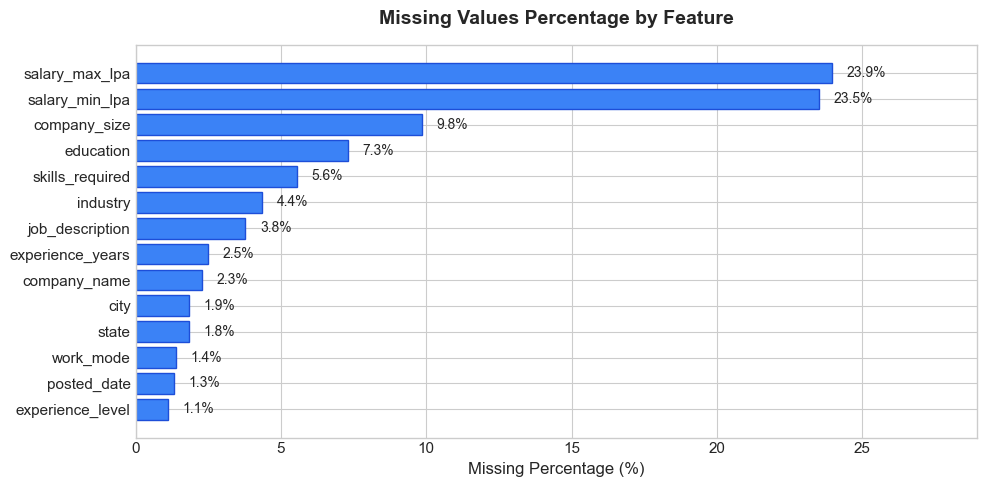

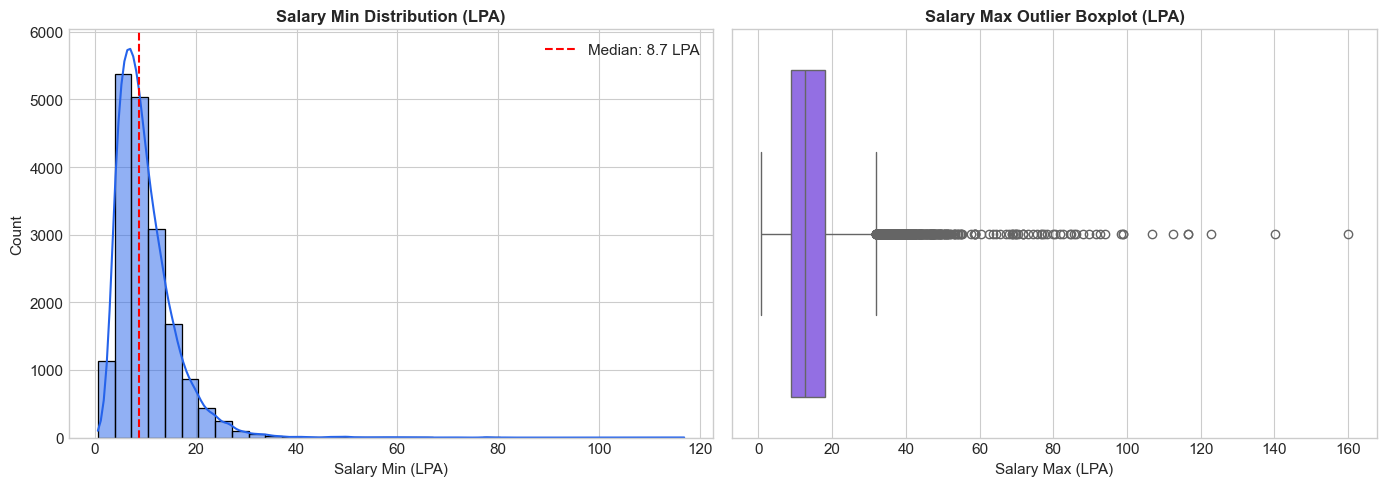

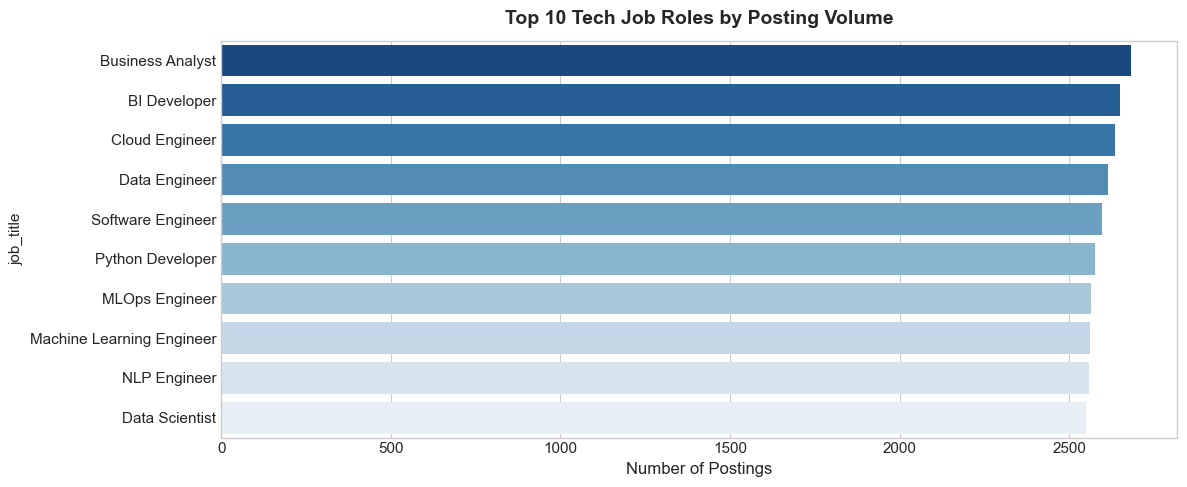

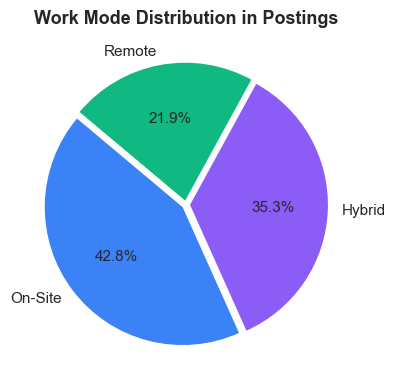

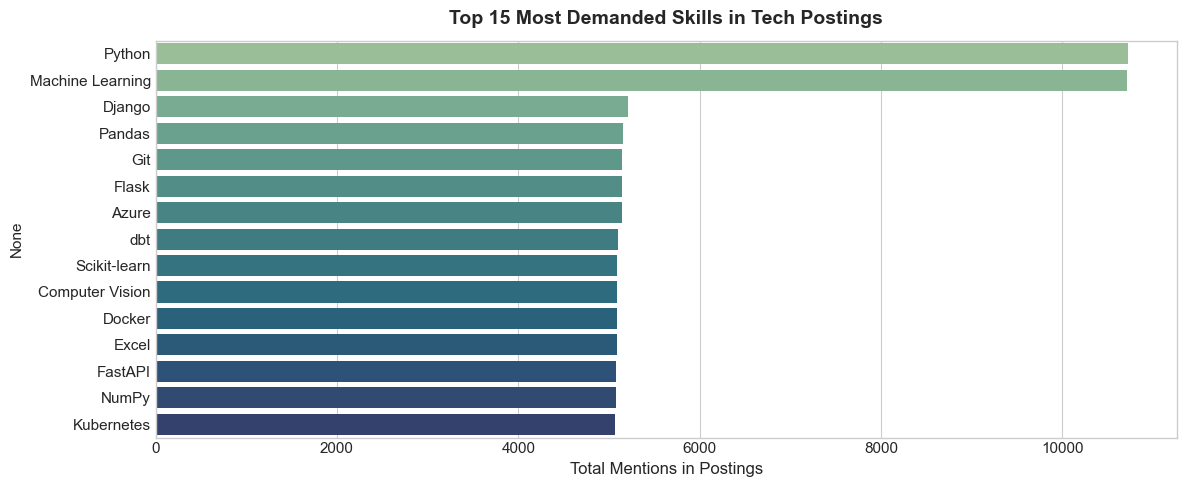

In [14]:
# 1. Missing Values Bar Chart
plt.figure(figsize=(10, 5))
missing_plot = missing_df['Missing Percentage (%)'].sort_values()
bars = plt.barh(missing_plot.index, missing_plot.values, color='#3B82F6', edgecolor='#1D4ED8')
plt.title('Missing Values Percentage by Feature', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Missing Percentage (%)', fontsize=12)
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.5, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', va='center', fontsize=10)
plt.xlim(0, max(missing_plot.values) + 5)
plt.tight_layout()
plt.show()

# 2. Salary Distribution (Valid Salaries Only)
valid_df = df[valid_sal_mask]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(valid_df['salary_min_lpa'], kde=True, ax=axes[0], color='#2563EB', bins=35)
axes[0].set_title('Salary Min Distribution (LPA)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Salary Min (LPA)')
axes[0].axvline(valid_df['salary_min_lpa'].median(), color='red', linestyle='--', label=f'Median: {valid_df["salary_min_lpa"].median():.1f} LPA')
axes[0].legend()

sns.boxplot(x=valid_df['salary_max_lpa'], ax=axes[1], color='#8B5CF6')
axes[1].set_title('Salary Max Outlier Boxplot (LPA)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Salary Max (LPA)')
plt.tight_layout()
plt.show()

# 3. Top 10 Job Roles
plt.figure(figsize=(12, 5))
top_roles = df['job_title'].value_counts().head(10)
sns.barplot(x=top_roles.values, y=top_roles.index, palette='Blues_r')
plt.title('Top 10 Tech Job Roles by Posting Volume', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Number of Postings', fontsize=12)
plt.tight_layout()
plt.show()

# 4. Work Mode Distribution
plt.figure(figsize=(8, 4))
mode_counts = df['work_mode'].dropna().str.strip().str.title().value_counts()
plt.pie(mode_counts, labels=mode_counts.index, autopct='%1.1f%%', colors=['#3B82F6', '#8B5CF6', '#10B981'], startangle=140, explode=[0.03, 0.03, 0.03])
plt.title('Work Mode Distribution in Postings', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# 5. Top 15 Technical Skills Bar Chart
plt.figure(figsize=(12, 5))
sns.barplot(x=top_skills.head(15).values, y=top_skills.head(15).index, palette='crest')
plt.title('Top 15 Most Demanded Skills in Tech Postings', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Total Mentions in Postings', fontsize=12)
plt.tight_layout()
plt.show()

### 14. Synthesis & Key Analytical Takeaways

#### 1. Dataset Overview
- **Scale:** 31,150 job postings spanning 20 columns across 16 major Indian tech hubs.
- **Posting Timeline:** Active listings from January 2024 through October 2026.
- **Key Roles:** 24 unique job titles led by Business Analyst, BI Developer, Cloud Engineer, Data Engineer, and Software Engineer.

#### 2. Data Quality Audit Findings
- **Exact Duplicates:** 900 records (2.89%) are 100% duplicate entries across all 20 fields.
- **Missing Values:** 14 out of 20 columns exhibit missing values, with the highest missingness in `salary_max_lpa` (23.95%) and `salary_min_lpa` (23.53%).
- **Salary Anomalies:** 35 negative minimum salary entries, 26 inverted ranges (`min > max`), and 11,184 postings with only one salary bound reported.
- **Experience Anomalies:** 5 negative experience years and 24 extreme values (>35 years, up to 99 years).
- **Categorical Inconsistencies:** Multiple variations in city names (e.g. `BANGALORE` vs `bengaluru`), work mode casing/spaces (`Hybrid `, `ON-SITE`), and experience level casing (`mid level`, `SENIOR`).

#### 3. Downstream Preprocessing Roadmap
1. **Deduplication:** Remove the 900 exact duplicates.
2. **Category Harmonization:** Canonicalize city names, work modes, employment types, and experience levels.
3. **Experience Repair:** Impute negative/extreme experience using experience level medians.
4. **Strict Salary Policy:** Isolate verified positive non-inverted salary records (~18k rows) for ML regression, calculating `salary_mid_lpa` and `salary_annual_inr`. Do not fabricate missing salaries for training.